In [1]:
!pip install shimmy>=0.2.1
!pip install stable_baselines3
!pip install stable-baselines3[extra]
!pip install gym
!pip install matplotlib

zsh:1: 0.2.1 not found
  Using cached stable_baselines3-2.9.2-py3-none-any.whl.metadata (4.9 kB)
  Using cached gymnasium-1.4.0-py3-none-any.whl.metadata (9.0 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached farama_notifications-0.0.6-py3-none-any.whl.metadata (729 bytes)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached stable_baselines3-2.9.2-py3-none-any.whl (188 kB)
Using cached gymnasium-1.4.0-py3-none-any.whl (476 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 9.5 MB/s  0:00:14m0:00:0100:01
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached farama_notifications-0.0.6-py3-none-any.whl (2.9 kB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)

In [23]:
# =========================
# IMPORTS
# =========================
import gymnasium as gym
import gym
from gym import spaces
from dataclasses import dataclass
from collections import deque
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import animation
from IPython.display import HTML
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from copy import deepcopy
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
import os
import sys
from stable_baselines3.common.callbacks import CheckpointCallback

## Environment

In [24]:
# Please if you want to acces the environment contact :
# mondelli.e.martin@gmail.com
# If you have it, you can paste it here and run it

# Mini Clash Royale-like Environment (Gym-style)
# NOTE: This is a realistic *structural* approximation, not a pixel-perfect clone.
# Focus: correct geometry (3 towers, 2 bridges), full card taxonomy, RL-ready.
sys.path.append(os.path.abspath(".gitignore"))
import Environment
MiniClashRoyaleEnv = Environment.MiniClashRoyaleEnv
ClashReplayRenderer = Environment.ClashReplayRenderer

## Multi-Agent competitive

In [25]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from copy import deepcopy

class MultiAgentWrapper(gym.Env):
    """
    Wrapper for using MiniClashRoyaleEnv with two PPO agents in a single MultiDiscrete action_space.
    Adjusted rewards so that both agents learn to play correctly.
    """

    # =========================
    # Reward Parameters (Easily adjustable)
    # =========================
    REWARD_BLUE_PLAY_SUCCESS = 10.0
    REWARD_BLUE_PLAY_ELIXIR_MULTIPLIER = 5.0
    PENALTY_BLUE_NO_CARDS = -1.0
    PENALTY_BLUE_BAD_PLACEMENT = -50.0
    PENALTY_BLUE_NO_ELIXIR = -8.0

    REWARD_RED_NO_PLAY = 0.5
    PENALTY_BLUE_RED_PLAY_SUCCESS = 0.0 # Penalty for blue if red plays successfully
    PENALTY_BLUE_RED_PLAY_ELIXIR_MULTIPLIER = 0.0
    REWARD_BLUE_RED_BAD_PLACEMENT = 0.0 # Reward for blue if red fails placement
    REWARD_BLUE_RED_NO_ELIXIR = 5.0 # Reward for blue if red has no elixir

    REWARD_DAMAGE_ENEMY_TOWER = 5.0
    PENALTY_DAMAGE_BLUE_TOWER = -5.0

    PENALTY_TIME = -0.01

    REWARD_KING_DESTROYED = 20.0
    PENALTY_KING_LOST = -20.0
    REWARD_HP_DIFFERENCE_TIMEOUT = 0.001

    REWARD_CLIP_MIN = -50.0
    REWARD_CLIP_MAX = 50.0

    def __init__(self, env, debug=False):
        super().__init__()
        self.env = env
        self.debug = debug

        # Action space for both agents combined
        # Using global constants for ARENA_WIDTH and ARENA_HEIGHT
        self.action_space = spaces.MultiDiscrete([
            len(self.env.blue_initial_deck_names), ARENA_WIDTH, ARENA_HEIGHT,
            len(self.env.red_initial_deck_names), ARENA_WIDTH, ARENA_HEIGHT
        ])

        # Observation space for both agents combined
        # Using global constants for MAX_ELIXIR, MATCH_TIME, and CARD_LIST_MASTER
        max_possible_obs_value = max(
            MAX_ELIXIR, MATCH_TIME,
            max(t.hp for side_towers in self.env.towers.values() for t in side_towers.values()),
            len(CARD_LIST_MASTER)
        )
        self.observation_space = spaces.Box(
            low=0, high=float(max_possible_obs_value * 10), # Multiplier 10 is arbitrary but common for scaling
            shape=(self.env.observation_space.shape[0] * 2,),
            dtype=np.float32
        )

        # Status of the last successful play
        self.blue_card_played_successfully_status = False
        self.red_card_played_successfully_status = False

    def reset(self, seed=None, options=None):
        obs_blue, info = self.env.reset(seed=seed, options=options)
        obs_red = self.env._get_obs("red")

        self.blue_card_played_successfully_status = False
        self.red_card_played_successfully_status = False

        return np.concatenate([obs_blue, obs_red]), {}

    def step(self, action):
        # Save tower HPs before the step
        before_red_hp = sum(t.hp for t in self.env.towers["red"].values())
        before_blue_hp = sum(t.hp for t in self.env.towers["blue"].values())

        # Separate blue / red actions
        action_blue, action_red = action[:3], action[3:]

        reward_blue_step = 0.0

        # ======================
        # --- Blue Action ---
        # ======================
        card_id_blue, x_blue, y_blue = action_blue
        self.blue_card_played_successfully_status = False

        if len(self.env.hands["blue"]) == 0:
            reward_blue_step += self.PENALTY_BLUE_NO_CARDS
        else:
            # Restrict positions to the valid arena
            x_blue_valid = np.clip(x_blue, 0, ARENA_WIDTH-1)
            y_blue_valid = np.clip(y_blue, 0, RIVER_Y-1)  # Blue below the river
            card_id_blue_valid = np.clip(card_id_blue, 0, len(self.env.hands["blue"]) - 1)

            card_name_blue = self.env.hands["blue"][card_id_blue_valid]
            card_blue_obj = ALL_CARDS[card_name_blue]
            lane_blue = "left" if x_blue_valid < ARENA_WIDTH/2 else "right"

            if self.env.elixir["blue"] >= card_blue_obj.elixir:
                success = self.env._apply_card(card_name_blue, x_blue_valid, y_blue_valid, lane_blue, "blue")
                if success:
                    self.env.elixir["blue"] -= card_blue_obj.elixir
                    self.blue_card_played_successfully_status = True
                    reward_blue_step += self.REWARD_BLUE_PLAY_SUCCESS + self.REWARD_BLUE_PLAY_ELIXIR_MULTIPLIER * card_blue_obj.elixir
                else:
                    reward_blue_step += self.PENALTY_BLUE_BAD_PLACEMENT
            else:
                reward_blue_step += self.PENALTY_BLUE_NO_ELIXIR

        # ======================
        # --- Red Action ---
        # ======================
        card_id_red, x_red, y_red = action_red
        self.red_card_played_successfully_status = False

        if len(self.env.hands["red"]) == 0:
            reward_blue_step += self.REWARD_RED_NO_PLAY
        else:
            x_red_valid = np.clip(x_red, 0, ARENA_WIDTH-1)
            y_red_valid = np.clip(y_red, RIVER_Y+1, ARENA_HEIGHT-1)  # Red above the river
            card_id_red_valid = np.clip(card_id_red, 0, len(self.env.hands["red"]) - 1)

            card_name_red = self.env.hands["red"][card_id_red_valid]
            card_red_obj = ALL_CARDS[card_name_red]
            lane_red = "left" if x_red_valid < ARENA_WIDTH/2 else "right"

            if self.env.elixir["red"] >= card_red_obj.elixir:
                success = self.env._apply_card(card_name_red, x_red_valid, y_red_valid, lane_red, "red")
                if success:
                    self.env.elixir["red"] -= card_red_obj.elixir
                    self.red_card_played_successfully_status = True
                    reward_blue_step += self.PENALTY_BLUE_RED_PLAY_SUCCESS + self.PENALTY_BLUE_RED_PLAY_ELIXIR_MULTIPLIER * card_red_obj.elixir
                else:
                    reward_blue_step += self.REWARD_BLUE_RED_BAD_PLACEMENT
            else:
                reward_blue_step += self.REWARD_BLUE_RED_NO_ELIXIR

        # ======================
        # --- Game Tick ---
        # ======================
        self.env._simulate_tick()
        self.env.time -= 1

        # Combined observations
        obs_blue = self.env._get_obs("blue")
        obs_red = self.env._get_obs("red")
        obs = np.concatenate([obs_blue, obs_red])

        # Rewards for tower damage
        after_red_hp = sum(t.hp for t in self.env.towers["red"].values())
        after_blue_hp = sum(t.hp for t in self.env.towers["blue"].values())

        reward_blue_step += (before_red_hp - after_red_hp) * self.REWARD_DAMAGE_ENEMY_TOWER
        reward_blue_step += (before_blue_hp - after_blue_hp) * self.PENALTY_DAMAGE_BLUE_TOWER

        # Small penalty for time to speed up matches
        reward_blue_step += self.PENALTY_TIME

        # Terminate if game ended
        terminated = self.env._game_over()
        truncated = False

        if terminated:
            if self.env.towers["red"]["king"].is_destroyed:
                reward_blue_step += self.REWARD_KING_DESTROYED
            elif self.env.towers["blue"]["king"].is_destroyed:
                reward_blue_step += self.PENALTY_KING_LOST
            elif self.env.time <= 0:
                # Tower difference
                blue_hp_sum = sum(t.hp for t in self.env.towers["blue"].values())
                red_hp_sum = sum(t.hp for t in self.env.towers["red"].values())
                reward_blue_step += (blue_hp_sum - red_hp_sum) * self.REWARD_HP_DIFFERENCE_TIMEOUT

        # Clip reward for stability
        reward_blue_step = np.clip(reward_blue_step, self.REWARD_CLIP_MIN, self.REWARD_CLIP_MAX)

        return obs, reward_blue_step, terminated, truncated, {}

In [26]:
class CompetitiveWrapper(gym.Env):
    def __init__(self, env: MiniClashRoyaleEnv, opponent_policy=None, agent_side="blue"):
        super().__init__()
        self.env = env # This self.env is MultiAgentWrapper
        self.opponent_policy = opponent_policy
        self.agent_side = agent_side # 'blue' or 'red'
        self.opponent_side = "red" if self.agent_side == "blue" else "blue"

        # Observation space is for a single agent, should refer to the underlying MiniClashRoyaleEnv
        self.observation_space = self.env.env.observation_space

        # Action space is for a single agent
        self.action_space = spaces.MultiDiscrete([
            len(self.env.env.blue_initial_deck_names) if self.agent_side == "blue" else len(self.env.env.red_initial_deck_names),
            ARENA_WIDTH, ARENA_HEIGHT
        ])

    def reset(self, seed=None, options=None):
        # Call reset on the MultiAgentWrapper, then get the specific agent's observation from MiniClashRoyaleEnv
        obs_combined, info = self.env.reset(seed=seed, options=options)
        return self.env.env._get_obs(self.agent_side), info

    def step(self, action):
        # Here, we need to combine the current agent's action with the opponent's action
        # The opponent_policy will provide the action for the self.opponent_side

        # Get opponent's observation for its policy from the underlying MiniClashRoyaleEnv
        opponent_obs = self.env.env._get_obs(self.opponent_side)
        opponent_action, _ = self.opponent_policy.predict(opponent_obs, deterministic=True) if self.opponent_policy else self._get_random_opponent_action()

        # Combine actions into the format expected by MultiAgentWrapper
        full_action = [0] * 6 # Placeholder for 6 discrete values

        if self.agent_side == "blue":
            full_action[0:3] = action.tolist() if isinstance(action, np.ndarray) else action
            full_action[3:6] = opponent_action.tolist() if isinstance(opponent_action, np.ndarray) else opponent_action
        else: # agent_side == "red"
            full_action[0:3] = opponent_action.tolist() if isinstance(opponent_action, np.ndarray) else opponent_action
            full_action[3:6] = action.tolist() if isinstance(action, np.ndarray) else action

        # Now call the original MultiAgentWrapper's step with the combined action
        # The reward from MultiAgentWrapper is blue-centric, we need to adapt it.
        full_obs, multi_agent_reward, terminated, truncated, info = self.env.step(full_action)

        # Extract agent's observation from the underlying MiniClashRoyaleEnv
        agent_obs = self.env.env._get_obs(self.agent_side)

        # Custom reward calculation for the competitive agent
        # This will be simpler, based on game outcome from agent's perspective
        reward = 0.0
        if terminated:
            # Reward based on game outcome from the agent's perspective
            if self.agent_side == "blue":
                if self.env.env.towers["red"]["king"].is_destroyed: # Blue wins
                    reward += 1.0
                elif self.env.env.towers["blue"]["king"].is_destroyed: # Blue loses
                    reward -= 1.0
                elif self.env.env.time <= 0: # Timeout, check tower HP difference
                    blue_hp_sum = sum(t.hp for t in self.env.env.towers["blue"].values())
                    red_hp_sum = sum(t.hp for t in self.env.env.towers["red"].values())
                    reward += (blue_hp_sum - red_hp_sum) * 0.001
            else: # agent_side == "red"
                if self.env.env.towers["blue"]["king"].is_destroyed: # Red wins
                    reward += 1.0
                elif self.env.env.towers["red"]["king"].is_destroyed: # Red loses
                    reward -= 1.0
                elif self.env.env.time <= 0: # Timeout, check tower HP difference
                    blue_hp_sum = sum(t.hp for t in self.env.env.towers["blue"].values())
                    red_hp_sum = sum(t.hp for t in self.env.env.towers["red"].values())
                    reward += (red_hp_sum - blue_hp_sum) * 0.001 # Red wants to maximize its HP relative to blue
        else:
            # Small penalty for time to encourage faster games
            reward -= 0.001

        return agent_obs, reward, terminated, truncated, info

    def _get_random_opponent_action(self):
        # Generates a random action for the opponent
        if self.opponent_side == "blue":
            card_idx = np.random.randint(0, len(self.env.env.blue_initial_deck_names))
            x = np.random.randint(0, ARENA_WIDTH)
            y = np.random.randint(0, RIVER_Y - 1)
        else:
            card_idx = np.random.randint(0, len(self.env.env.red_initial_deck_names))
            x = np.random.randint(0, ARENA_WIDTH)
            y = np.random.randint(RIVER_Y + 1, ARENA_HEIGHT)
        return np.array([card_idx, x, y], dtype=int)

In [27]:
# Decks
custom_blue_deck_competitive = [
    "knight", "archers", "giant", "baby_dragon",
    "fireball", "zap", "cannon", "hog_rider"
]
custom_red_deck_competitive = [
    "knight", "archers", "giant", "baby_dragon",
    "fireball", "zap", "cannon", "hog_rider"
]

# Initialization with random policies
# Blue Agent
env_blue_raw = MiniClashRoyaleEnv(
    blue_initial_deck=custom_blue_deck_competitive,
    red_initial_deck=custom_red_deck_competitive
)

# Use CompetitiveWrapper so blue only sees his observation and his reward
env_blue = DummyVecEnv([lambda: CompetitiveWrapper(
    MultiAgentWrapper(env_blue_raw), # Wrap the MiniClashRoyaleEnv with MultiAgentWrapper first to handle combined actions
    opponent_policy=None, # Initially random opponent
    agent_side="blue"
)])
env_blue = VecNormalize(env_blue, norm_obs=True, norm_reward=True)

model_blue = PPO("MlpPolicy", env_blue, verbose=0, batch_size=64, n_steps=256, learning_rate=3e-4, gamma=0.99)
model_blue.save("initial_model_blue") # Save initial model as opponent

# Red Agent
env_red_raw = MiniClashRoyaleEnv(
    blue_initial_deck=custom_blue_deck_competitive,
    red_initial_deck=custom_red_deck_competitive
)

# For the red agent, the opponent is the blue agent (initially random)
env_red = DummyVecEnv([lambda: CompetitiveWrapper(
    MultiAgentWrapper(env_red_raw),
    opponent_policy=None, # Initially random opponent
    agent_side="red"
)])
env_red = VecNormalize(env_red, norm_obs=True, norm_reward=True)

model_red = PPO("MlpPolicy", env_red, verbose=0, batch_size=64, n_steps=256, learning_rate=3e-4, gamma=0.99)
model_red.save("initial_model_red") # Save initial model as opponent


# --- Self-Play Training Loop ---

In [28]:
# --- Adjustable Reward Parameters (for MultiAgentWrapper) ---

# Blue Agent Rewards (Positives for Blue)
MultiAgentWrapper.REWARD_BLUE_PLAY_SUCCESS = 10.0
MultiAgentWrapper.REWARD_BLUE_PLAY_ELIXIR_MULTIPLIER = 5.0
MultiAgentWrapper.REWARD_DAMAGE_ENEMY_TOWER = 5.0
MultiAgentWrapper.REWARD_KING_DESTROYED = 20.0

# Blue Agent Penalties (Negative for Blue)
MultiAgentWrapper.PENALTY_BLUE_NO_CARDS = -1.0
MultiAgentWrapper.PENALTY_BLUE_BAD_PLACEMENT = -50.0
MultiAgentWrapper.PENALTY_BLUE_NO_ELIXIR = -8.0
MultiAgentWrapper.PENALTY_DAMAGE_BLUE_TOWER = -5.0
MultiAgentWrapper.PENALTY_KING_LOST = -20.0
MultiAgentWrapper.PENALTY_TIME = -0.01

# Blue Agent Rewards/Penalties based on Red's actions
MultiAgentWrapper.PENALTY_BLUE_RED_PLAY_SUCCESS = 0.0 # Penalty for blue if red plays successfully (encourage defense)
MultiAgentWrapper.PENALTY_BLUE_RED_PLAY_ELIXIR_MULTIPLIER = 0.0 # Penalty multiplier based on red card's elixir
MultiAgentWrapper.REWARD_BLUE_RED_BAD_PLACEMENT = 0.0 # Reward for blue if red makes a bad placement
MultiAgentWrapper.REWARD_BLUE_RED_NO_ELIXIR = 5.0 # Reward for blue if red has no elixir

# --- Reward clipping limits (for training stability) ---
MultiAgentWrapper.REWARD_CLIP_MIN = -50.0
MultiAgentWrapper.REWARD_CLIP_MAX = 50.0

print("MultiAgentWrapper reward parameters have been updated. Remember to re-run the MultiAgentWrapper and training cells.")

MultiAgentWrapper reward parameters have been updated. Remember to re-run the MultiAgentWrapper and training cells.


In [29]:
# Define paths for saving models
BLUE_MODEL_PATH = "trained_model_blue"
RED_MODEL_PATH = "trained_model_red"

# Create a directory for models if it doesn't exist
os.makedirs("models", exist_ok=True)

# Initialize models (or load if already trained from a previous run)
model_blue = PPO.load("initial_model_blue", env=env_blue)
model_red = PPO.load("initial_model_red", env=env_red)

# Number of training iterations
TRAINING_ITERATIONS = 5 # Each iteration trains both agents for some timesteps
TIMESTEPS_PER_AGENT_PER_ITER = 50000 # Number of timesteps each agent trains in one iteration

print("Starting Self-Play Training...")

for i in range(TRAINING_ITERATIONS):
    print(f"\n--- Iteration {i+1}/{TRAINING_ITERATIONS} ---")

    # 1. Train Blue Agent against current Red Agent
    print(f"Training Blue Agent (iteration {i+1})... (Opponent: Red Agent from iteration {i})")
    # Update the opponent policy for the blue agent's environment
    env_blue.set_attr("opponent_policy", model_red, indices=None)

    # Checkpoint callback for blue agent
    checkpoint_callback_blue = CheckpointCallback(save_freq=TIMESTEPS_PER_AGENT_PER_ITER, save_path='./models/blue_checkpoints', name_prefix=f'blue_iter_{i+1}', verbose=0)
    model_blue.learn(total_timesteps=TIMESTEPS_PER_AGENT_PER_ITER, reset_num_timesteps=False, callback=checkpoint_callback_blue)
    model_blue.save(f"models/{BLUE_MODEL_PATH}_iter_{i+1}")

    # 2. Train Red Agent against current Blue Agent
    print(f"Training Red Agent (iteration {i+1})... (Opponent: Blue Agent from iteration {i+1})")
    # Update the opponent policy for the red agent's environment
    env_red.set_attr("opponent_policy", model_blue, indices=None)

    # Checkpoint callback for red agent
    checkpoint_callback_red = CheckpointCallback(save_freq=TIMESTEPS_PER_AGENT_PER_ITER, save_path='./models/red_checkpoints', name_prefix=f'red_iter_{i+1}', verbose=0)
    model_red.learn(total_timesteps=TIMESTEPS_PER_AGENT_PER_ITER, reset_num_timesteps=False, callback=checkpoint_callback_red)
    model_red.save(f"models/{RED_MODEL_PATH}_iter_{i+1}")

    # Optional: Periodically update the opponent for the next iteration
    # For this example, we'll use the *latest* trained model for the opponent in the next iteration

print("Self-Play Training Complete!")

# Save final models (optional, already saved per iteration)
model_blue.save(BLUE_MODEL_PATH)
model_red.save(RED_MODEL_PATH)

print(f"Final Blue Agent saved to {BLUE_MODEL_PATH}")
print(f"Final Red Agent saved to {RED_MODEL_PATH}")

Starting Self-Play Training...

--- Iteration 1/5 ---
Training Blue Agent (iteration 1)... (Opponent: Red Agent from iteration 0)
Training Red Agent (iteration 1)... (Opponent: Blue Agent from iteration 1)

--- Iteration 2/5 ---
Training Blue Agent (iteration 2)... (Opponent: Red Agent from iteration 1)
Training Red Agent (iteration 2)... (Opponent: Blue Agent from iteration 2)

--- Iteration 3/5 ---
Training Blue Agent (iteration 3)... (Opponent: Red Agent from iteration 2)
Training Red Agent (iteration 3)... (Opponent: Blue Agent from iteration 3)

--- Iteration 4/5 ---
Training Blue Agent (iteration 4)... (Opponent: Red Agent from iteration 3)
Training Red Agent (iteration 4)... (Opponent: Blue Agent from iteration 4)

--- Iteration 5/5 ---
Training Blue Agent (iteration 5)... (Opponent: Red Agent from iteration 4)
Training Red Agent (iteration 5)... (Opponent: Blue Agent from iteration 5)
Self-Play Training Complete!
Final Blue Agent saved to trained_model_blue
Final Red Agent save

In [30]:
# Save each final PPO model and its matching VecNormalize statistics.
model_blue.save("trained_model_blue")
env_blue.save("trained_model_blue_vecnormalize.pkl")

model_red.save("trained_model_red")
env_red.save("trained_model_red_vecnormalize.pkl")

print("Saved both model files and their VecNormalize statistics.")

Saved both model files and their VecNormalize statistics.


Starting simulation between agents...
Simulation finished after 121 steps.


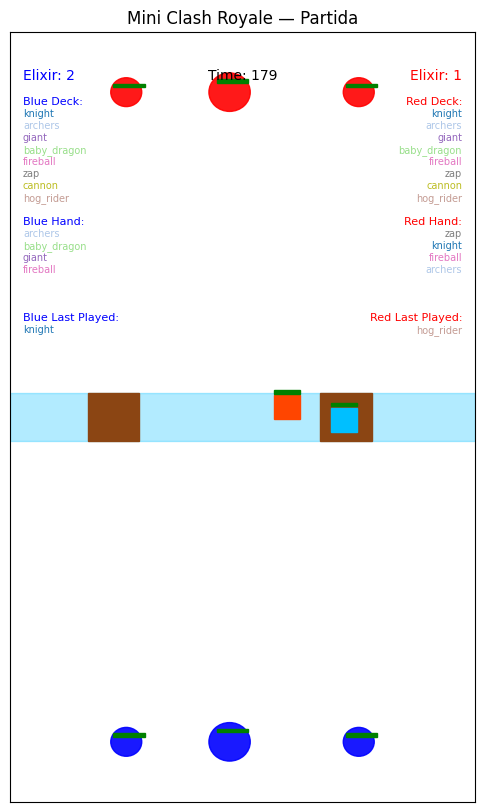

In [31]:
# --- Deck configuration for visualization (must match training) ---
blue_deck_viz = [
    "knight", "archers", "giant", "baby_dragon",
    "fireball", "zap", "cannon", "hog_rider"
]
red_deck_viz = [
    "knight", "archers", "giant", "baby_dragon",
    "fireball", "zap", "cannon", "hog_rider"
]

# --- Load trained models ---
# To correctly load models with their normalization statistics (VecNormalize),
# we must recreate the dummy training environment and pass it to PPO.load.

# Dummy environment to load the blue model and its normalization
raw_env_blue_for_normalize = MiniClashRoyaleEnv(blue_initial_deck=blue_deck_viz, red_initial_deck=red_deck_viz)
multi_env_blue_for_normalize = MultiAgentWrapper(raw_env_blue_for_normalize)
competitive_env_blue_for_normalize_base = CompetitiveWrapper(multi_env_blue_for_normalize, agent_side="blue")
vec_env_blue_for_normalize = VecNormalize(DummyVecEnv([lambda: competitive_env_blue_for_normalize_base]), training=False, norm_obs=True, norm_reward=True)
model_blue = PPO.load("trained_model_blue", env=vec_env_blue_for_normalize)

# Dummy environment to load the red model and its normalization
raw_env_red_for_normalize = MiniClashRoyaleEnv(blue_initial_deck=blue_deck_viz, red_initial_deck=red_deck_viz)
multi_env_red_for_normalize = MultiAgentWrapper(raw_env_red_for_normalize)
competitive_env_red_for_normalize_base = CompetitiveWrapper(multi_env_red_for_normalize, agent_side="red")
vec_env_red_for_normalize = VecNormalize(DummyVecEnv([lambda: competitive_env_red_for_normalize_base]), training=False, norm_obs=True, norm_reward=True)
model_red = PPO.load("trained_model_red", env=vec_env_red_for_normalize)

# --- Set up the actual game environment for visualization ---
# This 'raw' environment (MiniClashRoyaleEnv) will be the game state that is rendered.
# It is wrapped in MultiAgentWrapper to handle combined actions of both agents.
viz_env_raw = MiniClashRoyaleEnv(blue_initial_deck=blue_deck_viz, red_initial_deck=red_deck_viz)
viz_multi_agent_env = MultiAgentWrapper(viz_env_raw)

# Reset the environment for a new game
obs_multi_agent_current, _ = viz_multi_agent_env.reset() # This observation is combined

frames = []
done = False
current_step = 0
MAX_VIZ_STEPS = 300 # Limit the number of steps for animation duration

print("Starting simulation between agents...")

# --- Simulation Loop ---
while not done and current_step < MAX_VIZ_STEPS:
    # Get observation for the blue agent from the underlying MiniClashRoyaleEnv
    # This is the 'raw' observation that model_blue expects *before* normalization
    obs_blue_agent_raw = viz_env_raw._get_obs("blue")
    # Normalize the observation using the VecNormalize associated with model_blue
    # VecNormalize expects a batch, so resize the raw obs if necessary (it is 1D)
    obs_blue_agent_normalized = model_blue.env.normalize_obs(obs_blue_agent_raw[None, ...]) # Add a batch dimension

    # Predict the blue agent's action
    action_blue_agent, _ = model_blue.predict(obs_blue_agent_normalized, deterministic=True)

    # Get observation for the red agent
    obs_red_agent_raw = viz_env_raw._get_obs("red")
    # Normalize the observation using the VecNormalize associated with model_red
    obs_red_agent_normalized = model_red.env.normalize_obs(obs_red_agent_raw[None, ...])

    # Predict the red agent's action
    action_red_agent, _ = model_red.predict(obs_red_agent_normalized, deterministic=True)

    # Combine actions for the MultiAgentWrapper
    full_action = np.concatenate((action_blue_agent[0], action_red_agent[0]))

    # Advance the MultiAgentWrapper environment
    obs_multi_agent_current, reward, terminated, truncated, info = viz_multi_agent_env.step(full_action)
    done = terminated # MultiAgentWrapper's step returns a direct boolean for terminated

    # Store a deep copy of the current state of the raw MiniClashRoyaleEnv for rendering
    frames.append({
        "units": deepcopy(viz_env_raw.units),
        "towers": deepcopy(viz_env_raw.towers),
        "hands": deepcopy(viz_env_raw.hands),
        "elixir": deepcopy(viz_env_raw.elixir),
        "time": viz_env_raw.time,
        "last_cards_played": deepcopy(viz_env_raw.last_cards_played),
        "blue_initial_deck_names": list(viz_env_raw.blue_initial_deck_names),
        "red_initial_deck_names": list(viz_env_raw.red_initial_deck_names)
    })
    current_step += 1

print(f"Simulation finished after {current_step} steps.")

# --- Animation ---
fig, ax = plt.subplots(figsize=(6,10))
# The renderer expects a MiniClashRoyaleEnv instance
renderer = ClashReplayRenderer(viz_env_raw, fig, ax)

def animate_competitive(i):
    if i >= len(frames):
        return []
    current_frame_state = frames[i]

    # Restore the state of the raw MiniClashRoyaleEnv
    viz_env_raw.units = current_frame_state["units"]
    viz_env_raw.towers = current_frame_state["towers"]
    viz_env_raw.hands = current_frame_state["hands"]
    viz_env_raw.elixir = current_frame_state["elixir"]
    viz_env_raw.time = current_frame_state["time"]
    viz_env_raw.last_cards_played = current_frame_state["last_cards_played"]
    viz_env_raw.blue_initial_deck_names = current_frame_state["blue_initial_deck_names"]
    viz_env_raw.red_initial_deck_names = current_frame_state["red_initial_deck_names"]

    renderer.render()
    return []

ani = animation.FuncAnimation(fig, animate_competitive, frames=len(frames), blit=False, repeat=False)
HTML(ani.to_jshtml())